# Musterlösung (Knee-Phantom): Phasenfarben, Signalanteile und B₀-Karte

Diese Musterlösung folgt der aktuellen Aufgabenfassung `experiment.ipynb`. Alle Ergänzungsaufgaben und Kurzantworten sind ausgefüllt. Zusätzliche Codekommentare erklären die Rechenschritte, Einheiten und die Interpretation der Bilder.

Verwendet werden die Dual- und Triple-Echo-Daten des **Knee-Phantoms** aus `daten/knee/` (eine Schichtebene, 864 × 864 Pixel, Messung vom 05.11.2026). Die Musterlösung `experiment_loesung.ipynb` rechnet dieselben Schritte mit der Wasser-/Ölflasche; hier ändern sich nur Datenordner, Referenzdatei und die Kontrollwerte am Ende. Für den chemischen Frequenzabstand gilt die Skriptannahme von **3,5 ppm**, weil hier keine eigene Spektralmessung vorliegt. Echozeiten und Scannerfrequenz werden aus den DICOM-Metadaten gelesen.

Führen Sie die Zellen von oben nach unten aus. Sämtliche Abbildungen und Ergebnisse stehen direkt in den Zellenausgaben und werden mit dem Notebook gespeichert.

## Vorbereitung

Führen Sie bei Bedarf die Installationszelle aus. Starten Sie danach den Kernel neu und führen Sie anschließend die **Importzelle darunter** aus. Sind die Bibliotheken bereits installiert, beginnen Sie direkt bei den Importen.

In [ ]:
%pip install -r requirements-jupyterhub.txt
# %pip installiert die Bibliotheken in die Umgebung des aktiven Notebook-Kernels.
# Nach einer erstmaligen Installation den Kernel neu starten und die Importe ausführen.

In [1]:
from pathlib import Path       # Dateipfade unabhängig vom Betriebssystem zusammensetzen
import numpy as np             # Pixelweise Rechnungen auf ganzen Bildern
import pydicom                 # DICOM-Dateien und ihre Metadaten lesen
import matplotlib.pyplot as plt
import mrt_hilfen as mh         # Import-, Paarprüfungs- und Darstellungsfunktionen

print("Bibliotheken geladen.")

Bibliotheken geladen.


## Daten laden und verstehen

| Begriff | Bedeutung in diesem Notebook |
| --- | --- |
| Echo / TE | Ein Bild wird zu einer bestimmten Echozeit TE aufgenommen. |
| Magnitude | Die Stärke des gemessenen Signals, dargestellt als Helligkeit. |
| Phase | Die Winkellage des Signals; hier nach dem Import in Radiant (rad). |
| IP / OP | Wasser und Fett schwingen ungefähr gleichphasig / gegenphasig. |
| DICOM-Metadaten | Begleitinformationen wie Echozeit, Bildtyp und Bildgeometrie. |

Die erste Datei legt die Schichtebene fest. Der Katalog sucht dazu passende Bilder. **Echonummer und IP/OP sind nicht dasselbe:** Entscheidend sind die tatsächliche TE und der Wasser-Fett-Frequenzabstand.

In [2]:
datenordner = "daten/knee"
referenzdatei = Path(datenordner) / "knee_dual_echo2_magnitude.dcm"

# Die Referenzdatei legt genau eine Schichtebene fest.
dicom = pydicom.dcmread(referenzdatei)
# Der Katalog behält Bilder mit übereinstimmender Position und Geometrie.
katalog = mh.katalog(datenordner, referenz=dicom)
# Knee-Phantom: dieselben Echozeiten wie beim Flaschenbeispiel, frühes Echo als OP, spätes Echo als IP.
auswahl = mh.echo_auswahl(katalog, "T1W_FFE dual echo")

Beim Knee-Phantom ist das frühe Echo (6,9 ms) näherungsweise OP, das späte (13,8 ms) IP. Lassen Sie die Voreinstellung für den ersten Durchlauf stehen. Nach einer Änderung der Auswahl müssen Sie die folgende Zelle und alle nachfolgenden Zellen erneut ausführen.

Die Hilfsdatei prüft, ob die Bilder zur selben Aufnahme und Schichtebene gehören. Sie berechnet die Aufgaben dieses Notebooks nicht für Sie.

In [3]:
# Magnituden und zugehörige Phasen müssen zur selben Aufnahme, Ebene und TE gehören.
# Der Import übernimmt Skalierung und Paarprüfung; die Phasen werden in rad geladen.
op, ip, meta_op, meta_ip = mh.lade_paar(auswahl)
phase_op, meta_phase_op = mh.phase_zu_magnitude(katalog, meta_op)
phase_ip, meta_phase_ip = mh.phase_zu_magnitude(katalog, meta_ip)

print("Bildform [Zeilen, Spalten]:", ip.shape)
print("TE OP / IP [ms]:", meta_op["echozeit_ms"], meta_ip["echozeit_ms"])
print("Einheit der Phasen:", meta_phase_op["einheit"], meta_phase_ip["einheit"])

T1W_FFE dual echo | TE 6.901 / 13.8 ms | eine Ebene, 864 × 864 Pixel
Bildform [Zeilen, Spalten]: (864, 864)
TE OP / IP [ms]: 6.901 13.8
Einheit der Phasen: rad rad


### Magnitude und Phase vergleichen

Führen Sie die folgenden vier Darstellungszellen einzeln aus. **Jedes Bild erhält eine eigene Abbildung.** Vergleichen Sie jeweils dieselben Bildorte.

Die Magnitudenbilder verwenden dieselbe Grauwertskala, die Phasenbilder dieselbe Winkelskala. Helligkeit ist keine Wasser-/Fett-Kennzeichnung. Die Phase im signalarmen Hintergrund ist unzuverlässig.

**IP-Magnitude** · Signalstärke beim näherungsweise gleichphasigen Echo.

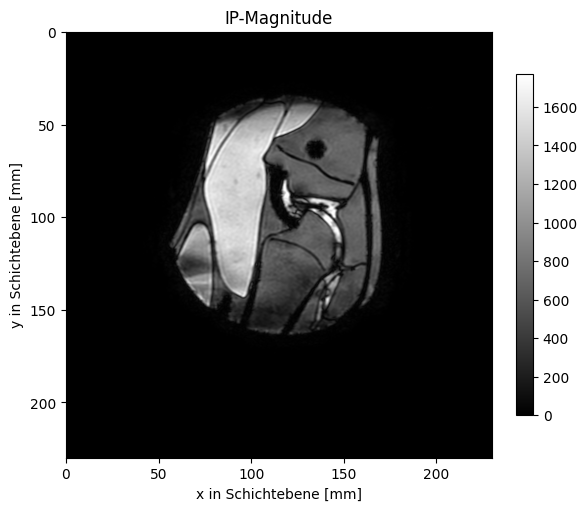

In [4]:
# Ein gemeinsames 99. Perzentil legt die obere Anzeigegrenze beider Magnituden fest.
# Die Pixelwerte selbst werden dabei nicht verändert.
signalgrenze = mh.fenster(ip, op)[1]
# Die Metadaten ermöglichen Achsen in Millimetern statt Pixelindizes.
fig_ip_magnitude = mh.bild(ip, "IP-Magnitude", meta_ip, (0, signalgrenze))

**OP-Magnitude** · Dieselbe Grauwertskala wie beim IP-Bild. Achten Sie auf Signalverluste.

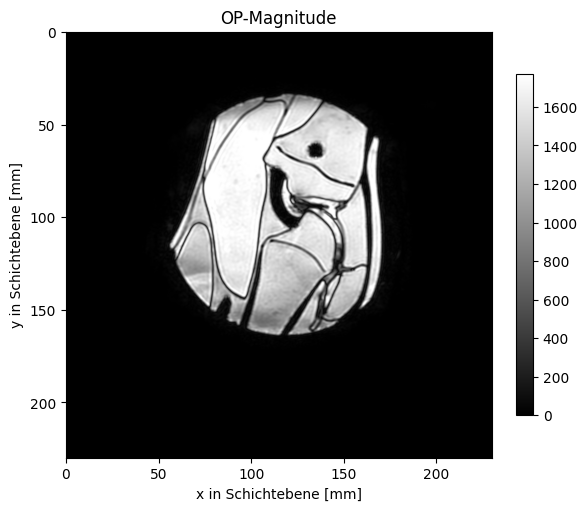

In [5]:
# Dieselbe Grauwertskala wie bei IP: Nur so sind Helligkeiten direkt vergleichbar.
fig_op_magnitude = mh.bild(op, "OP-Magnitude", meta_op, (0, signalgrenze))

**IP-Phase** · Die Farbe zeigt den Signalwinkel in Radiant.

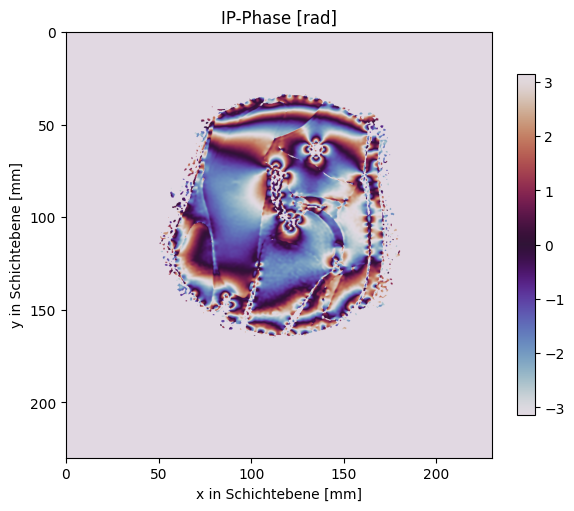

In [6]:
# Die importierte Phase liegt in Radiant vor. Die zyklische Farbskala zeigt Winkel.
# -pi und +pi beschreiben dieselbe Richtung; dort kann ein Farbsprung auftreten.
fig_ip_phase = mh.bild(phase_ip, "IP-Phase [rad]", meta_phase_ip, (-np.pi, np.pi), "twilight")

**OP-Phase** · Dieselbe Winkelskala wie beim IP-Phasenbild.

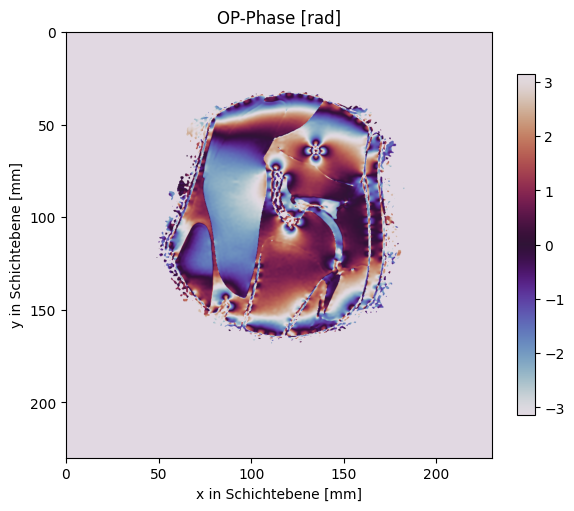

In [7]:
# Gleiche Winkelskala wie beim IP-Phasenbild; keine eigene Bildnormierung.
fig_op_phase = mh.bild(phase_op, "OP-Phase [rad]", meta_phase_op, (-np.pi, np.pi), "twilight")

## Physikalische Grundlage

**IP bedeutet nicht „nur Wasser“.** Im idealen, hintergrundphasenkorrigierten Modell gilt $S_\mathrm{IP}=W+F$ und $S_\mathrm{OP}=W-F$. Ein Magnitudenbild zeigt nur den Betrag:

$$M_\mathrm{IP}=W+F,\qquad M_\mathrm{OP}=|W-F|.$$

Die Magnituden verlieren das Vorzeichen von $W-F$. Deshalb liefern sie zunächst einen größeren und einen kleineren Modellanteil, ohne deren Wasser-/Fett-Zuordnung festzulegen.

Für das Farbbild verwenden wir separat die gemessene Phasendifferenz zwischen OP und IP. **Rot und Blau kennzeichnen ausschließlich Phasenlagen.** Die Farben erhalten keine feste Wasser-/Öl-Bedeutung; dadurch lassen sich eigene Aufnahmen ohne zusätzliche Kalibrierdatei verwenden.

Die Beispiel-Echozeiten sind nur näherungsweise IP und OP. Die vorbereitete Kontrolle berechnet die chemischen Umdrehungen aus TE und der Skriptannahme von 3,5 ppm. Eine ganze Umdrehungszahl passt zu IP, eine halbe zu OP. Das ist eine Modellprüfung, keine Spektralmessung.

In [8]:
# ImagingFrequency aus DICOM: Referenzfrequenz des Scanners in MHz.
F0 = meta_ip["referenz_mhz"]
# 3,5 ppm ist hier die Skriptannahme, kein gemessener Peakabstand.
# Ein gemessener Frequenzabstand aus Experiment 1 würde chemie_hz direkt ersetzen.
chemischer_shift_ppm = 3.5
chemie_hz = chemischer_shift_ppm * F0  # ppm × MHz = Hz

# Die tatsächlichen Echozeiten stehen in den Metadaten in Millisekunden.
OP_TE = meta_op["echozeit_ms"]
IP_TE = meta_ip["echozeit_ms"]
# Umdrehungen = Frequenz [1/s] × Zeit [s]; daher zuerst ms durch 1000 teilen.
# IP wird mit IP_TE berechnet, OP mit OP_TE.
Umdrehung_IP = IP_TE * chemie_hz / 1000
Umdrehung_OP = OP_TE * chemie_hz / 1000
print("Chemische Umdrehungen OP / IP:", Umdrehung_OP, Umdrehung_IP)

Chemische Umdrehungen OP / IP: 1.543440725848 3.0864341424000004


### Welche Pixel sind auswertbar?

Eine automatische **Signalmaske** schließt schwaches Signal aus. Ein Pixel ist nur gültig, wenn beide Echos genügend Signal und endliche Werte besitzen. Die Schwelle beträgt jeweils 15 % des 99. Perzentils; sie ist eine einfache Heuristik.

Die Maske wird bereitgestellt. Außerhalb der Maske steht in den Rechenarrays `NaN`: „kein auswertbarer Zahlenwert“. Sie müssen keine Bildbereiche von Hand auswählen.

In [9]:
# np.isfinite schließt NaN und unendliche Werte aus.
# Für die Phase verlangen wir zusätzlich genügend Signal in beiden Echos.
signal_ip = np.isfinite(ip) & (ip > 0.15 * np.percentile(ip, 99))
maske = (signal_ip & np.isfinite(op) & np.isfinite(phase_ip) & np.isfinite(phase_op)
         & (op > 0.15 * np.percentile(op, 99)))
if not maske.any():
    raise ValueError("Kein gemeinsamer signalstarker Bereich in beiden Echos.")
# Diese Arrays behalten die ganze Bildform; ungültige Pixel werden zu NaN.
# So sind die späteren Signalanteile nur an gültigen Bildorten definiert.
ip_signal = np.where(maske, ip, np.nan)
op_signal = np.where(maske, op, np.nan)
print("Auswertbare Pixel:", int(maske.sum()))

Auswertbare Pixel: 137656


## 12d · Phase als Farbe, Magnitude als Helligkeit

### Aufgabe 1: Die relative Phase berechnen

Ziehen Sie die IP-Phase von der OP-Phase ab. Winkel wiederholen sich nach $2\pi$. Führen Sie die Differenz deshalb auf den Bereich von $-\pi$ bis $\pi$ zurück:

$$\Delta\phi=\arg\{\exp[i(\phi_\mathrm{OP}-\phi_\mathrm{IP})]\}.$$

**Python-Hilfe:** `np.angle(z)` liefert den Winkel einer komplexen Zahl, `np.exp(...)` die Exponentialfunktion; `1j` ist die imaginäre Einheit. Ergänzen Sie die eine Rechenzeile. Es wird kein festgelegter Wasserbereich und kein vorgegebener Phasenoffset benötigt.

In [10]:
# Die gemessene OP-/IP-Phasendifferenz direkt für die Farben verwenden.
# exp(i*Winkel) berücksichtigt volle Umdrehungen; angle liefert [-pi, pi].
# Die neutrale Farbansicht benötigt keinen Kalibrierwert oder Wasser-Referenzbereich.
delta_phase = np.angle(np.exp(1j * (phase_op - phase_ip)))

### Aufgabe 2: Farbe und Helligkeit zusammensetzen

Berechnen Sie zwei **Farbgewichte**: $r=(1-\cos\Delta\phi)/2$ und $b=1-r$. Bei gleicher Phase wird das Bild blau, bei entgegengesetzter Phase rot. Die Farben sind neutrale Darstellungsfarben und keine Stoffkennzeichnung.

Die Helligkeit $h$ ist die IP-Magnitude geteilt durch `signalgrenze`. Begrenzen Sie **nur diese Anzeigegröße** mit `np.clip(..., 0, 1)`. Multiplizieren Sie das rote bzw. blaue Gewicht mit $h$:

$$\mathrm{RGB}=(h\,r,\;0,\;h\,b).$$

Ergänzen Sie die fünf Ausdrücke. Das Zusammensetzen der Farbkanäle und die Darstellung sind vorbereitet.

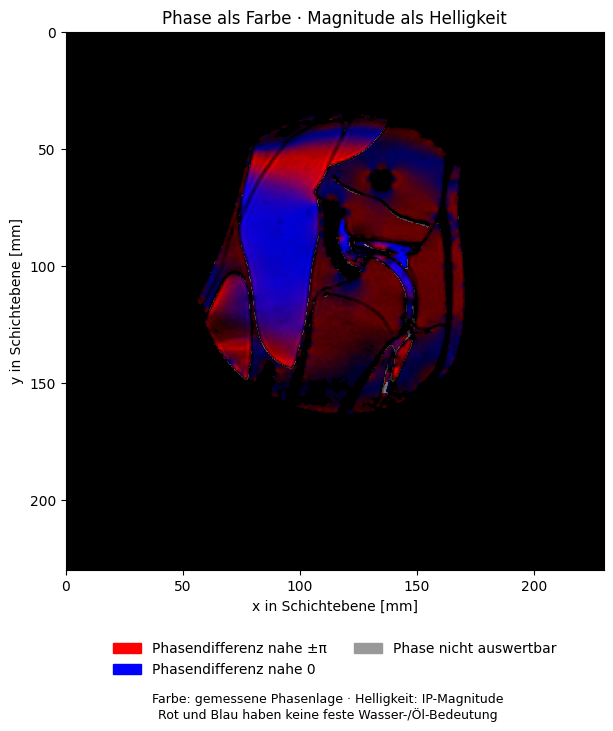

In [11]:
# Gleiche relative Phase: cos(0)=1 -> blau. Gegenphase: cos(pi)=-1 -> rot.
# Diese Größen beschreiben Phasenlagen; Rot und Blau sind keine Stoffkennzeichnung.
gewicht_rot = (1 - np.cos(delta_phase)) / 2
gewicht_blau = 1 - gewicht_rot

# Nur die Helligkeit der Anzeige wird auf [0, 1] begrenzt.
# Die ursprünglichen Magnituden für die Signalrechnung bleiben unverändert.
helligkeit = np.clip(ip / signalgrenze, 0, 1)
rot = helligkeit * gewicht_rot
blau = helligkeit * gewicht_blau

# RGB benötigt drei Kanäle: Rot, Grün, Blau. Grün bleibt hier null.
rgb = np.stack((rot, np.zeros_like(rot), blau), axis=-1)
rgb[~maske] = 0
# IP-Signal ohne gültige Phase wird grau dargestellt, schwacher Hintergrund schwarz.
grau = signal_ip & ~maske
rgb[grau] = helligkeit[grau, None]
fig_farbe = mh.phasenblend_anzeigen(rgb, meta_ip)

### So lesen Sie das Farbbild

| Farbe | Aussage |
| --- | --- |
| Blau | Die gemessene OP-/IP-Phasendifferenz liegt nahe null. |
| Rot | Die Phasendifferenz liegt nahe ±π. |
| Violett | Die Phase liegt dazwischen. |
| Grau | IP-Signal ist vorhanden, die Phase ist hier nicht auswertbar. |
| Schwarz | Zu wenig IP-Signal. |

Die beiden Farben zeigen Phasenunterschiede, **keine eindeutige Wasser-/Fett-Verteilung**. Im Knee-Phantom wechseln die Farben zwischen den Kammern; zusätzlich zeigen sich Feldabweichungen um die Kammerwände und die Bohrung. Ein Farbgewicht ist auch kein Signal- oder Mengenanteil. Feldabweichungen und echoabhängige Phasenfehler beeinflussen die Farben. Bei anderen Aufnahmen dürfen dieselben Flüssigkeiten deshalb anders eingefärbt sein.

Im nächsten Schritt berechnen Sie die Modellanteile direkt aus den Magnituden. Diese Rechnung verwendet die Farbdarstellung nicht.

## 13 · Größeren und kleineren Signalanteil pro Pixel berechnen

### Aufgabe 3: Die Magnituden auswerten

Aus dem vereinfachten Magnitudenmodell folgen ein größerer Anteil $A$ und ein kleinerer Anteil $B$:

$$A=\frac{M_\mathrm{IP}+M_\mathrm{OP}}{2},\qquad
B=\frac{M_\mathrm{IP}-M_\mathrm{OP}}{2},\qquad
p_B=100\,\frac{B}{A+B}.$$

Berechnen Sie die drei Größen mit `ip_signal` und `op_signal`. Die Rechnung erfolgt für jedes gültige Pixel. Sie benötigt keinen Phasenbezug.

**A ist nicht automatisch Wasser und B nicht automatisch Fett.** Im idealen Modell ist A der größere und B der kleinere der beiden Beiträge. Wasser und Fett können ihre Rollen tauschen, ohne die Magnituden zu ändern. Eine Stoffzuordnung würde zusätzliches Wissen erfordern und wird hier nicht vorgenommen.

Im idealen Modell liegt $p_B$ zwischen 0 und 50 %. Lassen Sie negative Signale oder Werte außerhalb dieses Intervalls stehen; sie zeigen Grenzen des Modells. Verwenden Sie keinen Betrag und kein Abschneiden.

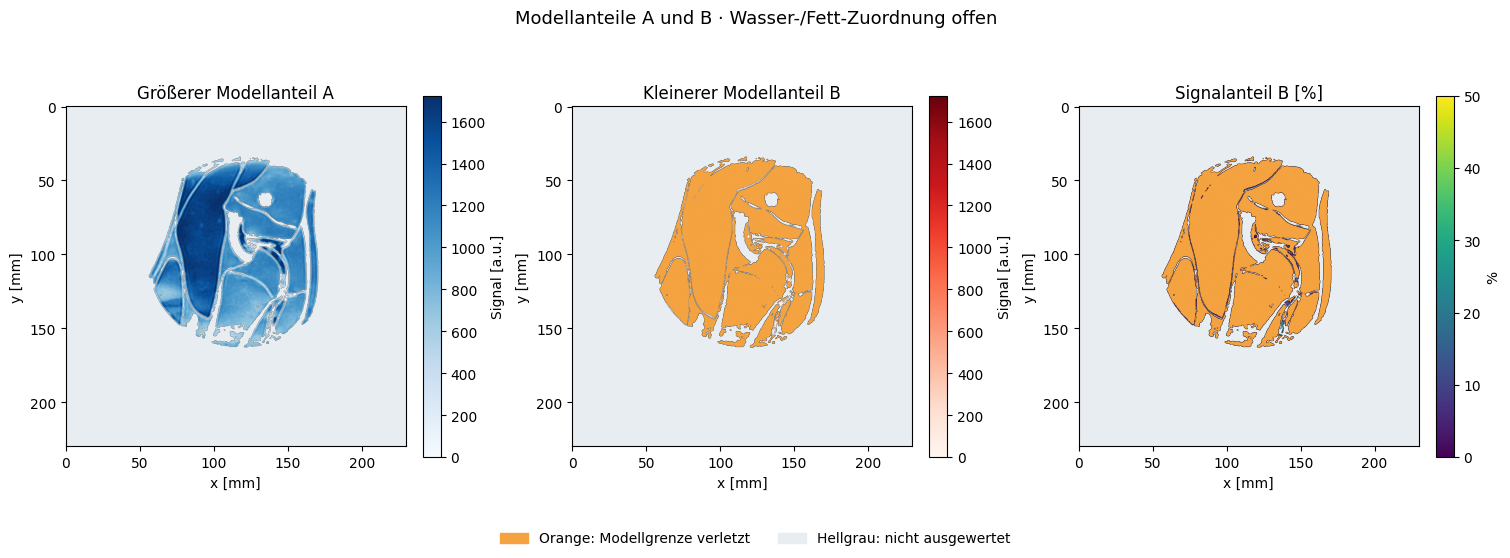

In [12]:
# Die Magnituden liefern zwei Modellanteile, deren Stoffzuordnung offen bleibt.
# A + B rekonstruiert IP; A - B rekonstruiert OP.
anteil_a = (ip_signal + op_signal) / 2
anteil_b = (ip_signal - op_signal) / 2
# B ist im idealen Modell der kleinere Beitrag; sein Anteil liegt dann bei 0 bis 50 %.
signalanteil_b_prozent = 100 * anteil_b / (anteil_a + anteil_b)

# Negative Werte bleiben als Hinweis auf Modellverletzungen sichtbar.
fig_signalanteile = mh.signalanteile_anzeigen(anteil_a, anteil_b, signalanteil_b_prozent, maske, meta_ip)

### Ergebnisse prüfen

Die ersten beiden Karten zeigen die Modellanteile A und B. Die dritte zeigt den Signalanteil B in Prozent. **Orange** markiert negative Signale oder Prozentwerte außerhalb von 0 bis 50; **Hellgrau** nicht ausgewertete Pixel.

Die folgende Kontrolle prüft die Bildform, die Farbgewichte und die Beziehungen A + B = IP sowie A − B = OP. Sie zählt außerdem Pixel mit einer Modellverletzung. Daraus wird keine Stoffkonzentration des Phantoms abgeleitet.

**Besonderheit des Knee-Phantoms:** Die Kontrolle meldet hier eine Modellverletzung für fast alle gültigen Pixel (etwa 98 %, beim Flaschenbeispiel rund 17 %). Die Kammern des Phantoms enthalten überwiegend jeweils nur eine Signalkomponente. Im idealen Modell wäre dann $M_\mathrm{OP}=M_\mathrm{IP}$ und $B=0$. Tatsächlich zerfällt das Signal zwischen 6,9 ms und 13,8 ms durch $T_2^*$, sodass das späte IP-Echo überall dunkler ist als das frühe OP-Echo und $B=(M_\mathrm{IP}-M_\mathrm{OP})/2$ negativ wird. Die Karte des Signalanteils B ist deshalb fast vollständig orange. Das ist kein Rechenfehler, sondern zeigt die Grenze des Zwei-Punkt-Magnitudenmodells ohne $T_2^*$-Korrektur. Die Phasenfarben im Abschnitt davor trennen die Kammern dagegen deutlich.

In [13]:
# Farbgewichte und Magnitudenrechnung werden unabhängig voneinander geprüft.
assert delta_phase.shape == ip.shape
assert rgb.shape == (*ip.shape, 3)
assert np.isfinite(rgb).all() and np.all((rgb >= 0) & (rgb <= 1))
np.testing.assert_allclose((gewicht_rot + gewicht_blau)[maske], 1)
np.testing.assert_allclose((anteil_a + anteil_b)[maske], ip[maske])
np.testing.assert_allclose((anteil_a - anteil_b)[maske], op[maske])
assert np.isfinite(signalanteil_b_prozent[maske]).all()
assert np.isnan(signalanteil_b_prozent[~maske]).all()
modellverletzung = maske & ((anteil_a < 0) | (anteil_b < 0))
modellverletzung_prozent = 100 * modellverletzung.sum() / maske.sum()
print("Gültige Pixel:", int(maske.sum()))
print("Davon Pixel mit Modellverletzung [%]:", float(modellverletzung_prozent))

Gültige Pixel: 137656
Davon Pixel mit Modellverletzung [%]: 97.90274306968094


### Kurzantworten der Musterlösung

1. **IP enthält beide Signalbeiträge.** Wasser und Fett addieren sich näherungsweise gleichphasig. Deshalb kann auch ein reiner Fett- bzw. Ölbereich eine hohe IP-Magnitude haben.
2. **Das Farbgewicht beschreibt nur die Phasenlage.** `gewicht_rot` wird aus der gemessenen Phasendifferenz berechnet und steuert den Rotkanal. `signalanteil_b_prozent` wird dagegen aus beiden Magnituden berechnet und beschreibt den kleineren Modellbeitrag relativ zu A + B.
3. **Die Zuordnung bleibt offen.** Die Mischungen W = 80, F = 20 und W = 20, F = 80 liefern im Idealmodell beide IP = 100 und OP = 60, also A = 80 und B = 20. A kann deshalb Wasser oder Fett sein. Die Phasenfarben werden hier ohne Kalibrierung dargestellt und hängen auch von Feldabweichungen und Phasenfehlern ab. Sie legen die Stoffzuordnung nicht fest. Die Anteile sind keine validierten Konzentrationen oder Volumenfraktionen.

## 14 · B₀-Karte aus der Triple-Echo-Aufnahme

Wir vergleichen **Echo 3 mit Echo 1**. Wenn sich die chemische Phasenentwicklung um eine ganze Anzahl Umdrehungen weiterbewegt hat, ist die relative Phase wieder ungefähr null. Die absolute Phase des dritten Bildes muss nicht null sein. Lokale Feldabweichungen erzeugen eine zusätzliche Phasendifferenz; daraus wird die Frequenzabweichung berechnet.

Das Laden ist vorbereitet. Verwenden Sie die äußeren Phasenbilder derselben Triple-Echo-Aufnahme. Die tatsächlichen Echozeiten werden aus DICOM gelesen.

In [14]:
# Die äußeren Triple-Echos sind näherungsweise chemisch gleichphasig.
# modus="b0" wählt Phasen statt Magnituden und sortiert sie nach tatsächlicher TE.
b0_auswahl = mh.echo_auswahl(katalog, "T1W_FFE triple echo", modus="b0")

In [15]:
# Es werden die Phasen von Echo 1 und Echo 3 derselben Triple-Aufnahme geladen.
b0_phase_1, b0_phase_3, b0_meta_1, b0_meta_3 = mh.lade_paar(b0_auswahl)

# Keine TE aus dem Dateinamen oder von Hand übernehmen: DICOM-Werte in ms lesen.
B0_TE_ECHO_1 = b0_meta_1["echozeit_ms"]
B0_TE_ECHO_3 = b0_meta_3["echozeit_ms"]

print("TE Echo 1 / Echo 3 [ms]:", B0_TE_ECHO_1, B0_TE_ECHO_3)
# Diese chemische Kontrolle nutzt die Skriptannahme aus dem Dual-Echo-Teil.
# Die eigentliche Frequenzkarte benötigt chemie_hz und F0 nicht.
print("Chemische Umdrehungen zwischen den Echos:", chemie_hz * (B0_TE_ECHO_3 - B0_TE_ECHO_1) / 1000)

T1W_FFE triple echo | TE 9.201 / 23.001 ms | eine Ebene, 864 × 864 Pixel
TE Echo 1 / Echo 3 [ms]: 9.201 23.001
Chemische Umdrehungen zwischen den Echos: 3.0864341424000004


### Aufgabe 4: Phasendifferenz → Frequenzabweichung → Karte

Berechnen Sie den Echoabstand in **Sekunden**, die Phasendifferenz in **Radiant** und daraus die Frequenzabweichung in **Hz**:

$$\Delta TE=(TE_3-TE_1)/1000,\qquad
\Delta\phi=\arg\{\exp[i(\phi_3-\phi_1)]\},\qquad
\Delta f=\frac{\Delta\phi}{2\pi\,\Delta TE}.$$

Ergänzen Sie die drei Rechenzeilen. Die vorbereitete Anzeige zeichnet die gesamte Schicht **ohne Maske**. Im signalarmen Hintergrund ist die Phase verrauscht; dort hat die Karte keine verlässliche Feldaussage.

Die Phasendifferenz liegt zwischen $-\pi$ und $\pi$. Ohne räumliches Entfalten ist die Frequenz daher nur modulo $1/\Delta TE$ bestimmt; Sprünge können Phasenumbrüche sein. Außerdem ist die chemische Gleichphasigkeit im Beispiel nur näherungsweise erfüllt. Die Karte ist eine einfache B₀-Darstellung in Hz, keine absolut kalibrierte Feldmessung. Das Vorzeichen folgt der Annahme $\phi=\phi_0+2\pi\,\Delta f\,TE$.

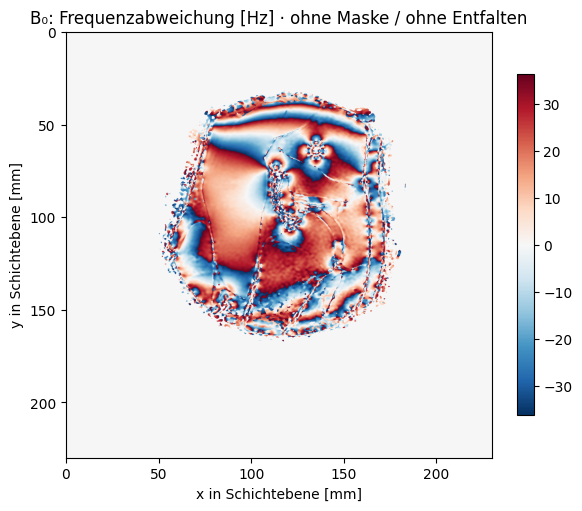

In [16]:
# Den gesamten Abstand zwischen Echo 1 und Echo 3 von ms nach s umrechnen.
delta_te_b0_s = (B0_TE_ECHO_3 - B0_TE_ECHO_1) / 1000
# Echo 3 wird relativ zu Echo 1 betrachtet; die absolute Startphase fällt heraus.
# angle(exp(i*Differenz)) liefert die gewickelte Differenz zwischen -pi und pi.
delta_phase_b0 = np.angle(np.exp(1j * (b0_phase_3 - b0_phase_1)))
# rad / (2*pi*s) ergibt Hz. Kein zusätzlicher Faktor 1/2 und kein F0 erforderlich.
b0_hz = delta_phase_b0 / (2 * np.pi * delta_te_b0_s)

# Ohne räumliches Entfalten ist nur dieses modulo-Intervall darstellbar.
b0_grenze_hz = 1 / (2 * delta_te_b0_s)
# Die ganze Schicht wird ohne Maske gezeigt; Hintergrundphase ist unzuverlässig.
fig_b0 = mh.bild(b0_hz, "B₀: Frequenzabweichung [Hz] · ohne Maske / ohne Entfalten",
                 b0_meta_1, (-b0_grenze_hz, b0_grenze_hz), "RdBu_r")

## Eigene Messdaten verwenden

Laden Sie Ihre DICOM-Dateien in `daten/eigene/` hoch. Sie benötigen Magnitude und Phase beider Echos auf derselben Schichtebene. Ersetzen Sie in der Ladezelle den Datenordner, den Dateipfad und die Aufnahme durch Ihre eigenen Daten. Dateinamen und Aufnahmebezeichnungen dürfen von den Beispielen abweichen; die Paarprüfung nutzt DICOM-Metadaten.

Führen Sie danach alle folgenden Zellen erneut aus. Die Farbformel verarbeitet auch gedrehte Objekte und benötigt keine zusätzliche Kalibrierdatei. Rot und Blau kennzeichnen nur die gemessene Phasenlage. Prüfen Sie für die Magnitudenrechnung weiterhin anhand der tatsächlichen Echozeiten und Ihres Messprotokolls, ob die Echos näherungsweise IP und OP entsprechen.

Für die B₀-Aufgabe benötigen Sie zusätzlich die Phasenbilder der äußeren Triple-Echos. Wählen Sie dort Ihre Triple-Echo-Aufnahme und kontrollieren Sie den tatsächlichen Echoabstand sowie die chemische Gleichphasigkeit.

### Hintergrund

Die Übung zeigt einen qualitativen Phasen-Magnitude-Blend und eine vereinfachte Signalaufteilung. Für eine belastbare komplexe Wasser-/Fett-Trennung müssen unter anderem räumliche Phasenfehler berücksichtigt werden: [Berglund et al., 2011: Two-point Dixon method with flexible echo times](https://doi.org/10.1002/mrm.22679).

Die Hilfsdatei übernimmt DICOM-Import, Skalierung, Paarprüfung und Darstellung. **Die Rechenschritte für Phase, Farbgewichte, Helligkeit und Signalanteile stehen sichtbar in Ihrem Notebook.**

Die B₀-Frequenzkarte folgt dem Zusammenhang zwischen Phasendifferenz und Echoabstand: [SDCFlows-Dokumentation](https://www.nipreps.org/sdcflows/1.4/_modules/sdcflows/workflows/fit/fieldmap.html). Hier wird bewusst die einfache, nicht räumlich entfaltete Darstellung gezeigt.

### Prüfung der Musterlösung

Die folgenden Kontrollen prüfen die Paarung der Echos, die TE-Zuordnung und die berechneten Signal- und Frequenzkarten. Die Zahlenwerte gelten für die 10 Dateien des Knee-Phantoms in `daten/knee/`.

In [17]:
# Magnituden und Phasen müssen zum selben Aufnahme-Paar und derselben Ebene gehören.
assert len(katalog) == 10
assert ip.shape == op.shape == (864, 864)
assert meta_op["aufnahme"] == meta_ip["aufnahme"] == "T1W_FFE dual echo"
assert mh.gleiche_geometrie(meta_op, meta_ip)
assert meta_phase_op["gruppe"] == meta_op["gruppe"]
assert meta_phase_ip["gruppe"] == meta_ip["gruppe"]

# Richtige Zuordnung der Echozeiten zu den chemischen Umdrehungen prüfen.
np.testing.assert_allclose(Umdrehung_IP, IP_TE * chemie_hz / 1000)
np.testing.assert_allclose(Umdrehung_OP, OP_TE * chemie_hz / 1000)
np.testing.assert_allclose((anteil_a - anteil_b)[maske], op_signal[maske])

# B0 verwendet tatsächlich die äußeren Phasen der Triple-Echo-Aufnahme.
assert b0_meta_1["aufnahme"] == b0_meta_3["aufnahme"] == "T1W_FFE triple echo"
assert b0_meta_1["gruppe"] == b0_meta_3["gruppe"]
assert mh.gleiche_geometrie(b0_meta_1, b0_meta_3)
b0_echos = sorted(m["echozeit_ms"] for m in katalog
                  if m["gruppe"] == b0_meta_1["gruppe"] and m["komponente"] == "PHASE")
assert len(b0_echos) == 3
assert B0_TE_ECHO_1 == b0_echos[0] and B0_TE_ECHO_3 == b0_echos[-1]
assert delta_te_b0_s > 0 and b0_hz.shape == ip.shape
# Die B0-Karte hat bewusst keine NaN-Maske und bleibt im gewickelten Intervall.
assert np.isfinite(b0_hz).all()
assert np.max(np.abs(b0_hz)) <= b0_grenze_hz + 1e-10
np.testing.assert_allclose(b0_hz * (2 * np.pi * delta_te_b0_s), delta_phase_b0)

print("Alle Kontrollen für das Knee-Phantom erfolgreich. Abbildungen und Ergebnisse stehen in den Notebook-Zellen.")
plt.close("all")

Alle Kontrollen für das Knee-Phantom erfolgreich. Abbildungen und Ergebnisse stehen in den Notebook-Zellen.
